Middleware woh layer/code hota hai jo Agent ke execution ke beech mein sit karta hai.

Iska fayda ye hai ki Agent ko result dene se pehle, Agent se result lene ke baad, ya model/tool call ke around hum apna custom logic perform kar sakte hain.

summarization middle ware 
will summariz the long chat conersation automaitcally to prevent the model from increasing token usage ...
also as the models have limited context window so if we give unneceraliy entire histroy thn model will forgot earlier things...
so thats why before giving the entire history to the model we can do summarize the conversation hsitory...

In [1]:
import os
from dotenv import load_dotenv

load_dotenv()

os.environ['GROQ_API_KEY']=os.getenv("GROQ_API_KEY")

os.environ['LANGCHAIN_API_KEY']=os.getenv("LANGCHAIN_API_KEY")

In [2]:
# summarization middle ware

from langchain.agents import create_agent
from langchain.agents.middleware import SummarizationMiddleware
from langchain_groq import ChatGroq
from langgraph.checkpoint.memory import InMemorySaver

llm=ChatGroq(
    model='openai/gpt-oss-20b',
    temperature=0
)

In [3]:
agent=create_agent(
    model=llm,
    checkpointer=InMemorySaver(),
    middleware=[
        SummarizationMiddleware(
            model=llm,
            trigger=("messages",10), # trigger this wehn my messages list becomes more thant 10 or atleast 10
            keep=("messages",4) # measn keep recent 4 messages as it is and summarize the previous ones...
        )
    ]
)

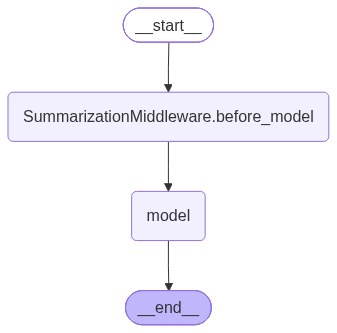

In [4]:
agent

In [5]:
from langchain.messages import HumanMessage

config={"configurable":{"thread_id":"test-1"}}

questions = [
    "My name is Azra and I am a Data Scientist.",
    "I work mainly with Python, SQL, Machine Learning and Power BI.",
    "I am currently learning LangChain and Generative AI.",
    "What is an AI agent?",
    "What is the difference between an agent and an LLM?",
    "What is a ReAct agent?",
    "What is a tool in an AI agent?",
    "How does an agent decide which tool to use?",
    "What is middleware in LangChain?",
    "What is SummarizationMiddleware?",
    "What technologies am I learning?",
    "What is my name and profession?"
]

for q in questions:
    response=agent.invoke({"messages":HumanMessage(content=q)},config=config)
    print(response["messages"][-1].content)

Nice to meet you, Azra! 👋 As a Data Scientist, you’re probably juggling a mix of data wrangling, modeling, and storytelling. What’s the most exciting project you’ve worked on lately, or is there a particular domain (e.g., healthcare, finance, NLP) you’re passionate about? If you’re looking for new ideas, tools, or just a quick sanity check on a model, feel free to share—happy to help!
Hey Azra! 👋  
It sounds like you’ve got a solid tech stack in place—Python, SQL, ML, and Power BI. I’d love to hear more about what you’re building right now. A few quick questions (and some quick‑fire tips) to get the conversation rolling:

| Area | What’s going on? | Quick Tips / Resources |
|------|------------------|------------------------|
| **Data ingestion & ETL** | Are you pulling data from a single database or multiple sources (e.g., on‑prem SQL Server, Snowflake, Azure Data Lake, APIs)? | • **SQLAlchemy** + **pandas** for ad‑hoc pulls.<br>• **dbt** for version‑controlled transformations.<br>• *